# Diabetes 130-US Hospitals - Cleaning, EDA, Preprocessing and Train/Test Split

- Part 1 (sections 1 to 11): we load the raw data, we clean it and we explore it.
- Part 2 (sections 12 to 20): we prepare the data for modelling and we split it by patient.

## 1. Imports and paths

In [4]:
#import os to handle paths and folders
import os
#import sys to add the src folder to the Python path
import sys
#import numpy for numerical operations
import numpy as np
#import pandas to manipulate the tables
import pandas as pd
#import matplotlib to draw the graphs
import matplotlib.pyplot as plt
#import seaborn for nicer graphs
import seaborn as sns
#import the splitter that keeps groups together and keeps the class proportions
from sklearn.model_selection import StratifiedGroupKFold
#use a simple style for all the graphs
sns.set_theme(style="whitegrid")
#show all the columns when we print a table
pd.set_option("display.max_columns", 60)
#link of the raw file in the group repository (a local path such as ../data/raw/diabetic_data.csv also works)
RAW_PATH = "https://raw.githubusercontent.com/AmandineBaranger/Group_06_DS_Project/main/data/raw/diabetic_data.csv"
#relative path of the folder where we save the cleaned data and the train and test files
PROCESSED_DIR = os.path.join("..", "data", "processed")
#relative path of the folder that contains our Python module
SRC_DIR = os.path.join("..", "src")
#fixed random seed so that the results can be reproduced
SEED = 42

We use relative paths for the outputs so the notebook runs on any computer without changes. The raw file is read from the group repository on GitHub but a local copy can be used by changing RAW_PATH. The random seed is fixed because the split in Part 2 uses a shuffle. Without a seed we would get a different split at each run and the results of the next notebooks could not be compared fairly.

The notebook must be started from the notebooks folder because the relative paths start with two dots.

# Part 1 - Data cleaning and exploratory analysis (EDA)
In this part we look at the raw data and we fix its problems. We also define the target and we make a first exploratory analysis.

## 2. Loading the raw data

In [9]:
#load the raw file (None stays a text and only the question marks become NaN)
df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"], low_memory=False)
#print the number of rows and columns
print("Shape :", df.shape)
#show the first rows
df.head()

Shape : (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,NaN,NaN,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,NaN,NaN,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [11]:
#count the number of columns of each type
print(df.dtypes.value_counts())
#show simple statistics of the numeric columns
df.describe().T

str      37
int64    13
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


What this code does: read_csv loads the raw file. Two options are important. na_values=["?"] tells pandas that a question mark is a missing value because this dataset writes its missing values with a question mark. keep_default_na=False switches off the default list of words that pandas reads as missing. Without it the text None would also become NaN. In the columns max_glu_serum and A1Cresult the text None means that the test was not done so it is real information and not a missing value. The option low_memory=False only removes a warning about mixed types in payer_code. After loading we print the shape and the first rows then we count the column types and we show simple statistics with describe.

How to read the results: the table has 101,766 rows and 50 columns. 37 columns are text and 13 are numeric. Some numeric columns are not real numbers. encounter_id and patient_nbr are identifiers and admission_type_id, discharge_disposition_id and admission_source_id are codes of categories. Treating a code as a number would be wrong because the code 6 is not twice the code 3. We convert them to categories in Part 2. The statistics show that a patient stays 4.4 days on average in the hospital with a maximum of 14 days and receives about 16 medications.

## 3. Missing values

Remaining question marks : 0
weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64


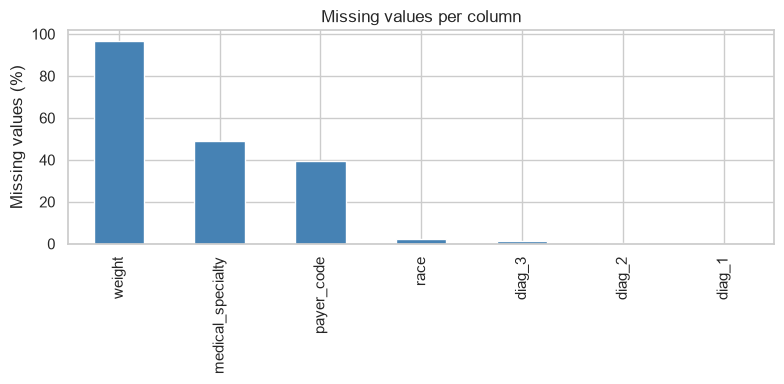

In [15]:
#check that no question mark is left in the table
print("Remaining question marks :", (df == "?").sum().sum())
#compute the percentage of missing values in each column
missing = df.isna().mean().mul(100).sort_values(ascending=False)
#keep only the columns that have missing values
missing = missing[missing > 0]
#print the percentages
print(missing.round(2))
#create the figure
plt.figure(figsize=(8, 4))
#draw one bar per column
missing.plot(kind="bar", color="steelblue")
#name the y axis
plt.ylabel("Missing values (%)")
#add a title
plt.title("Missing values per column")
#avoid overlapping texts
plt.tight_layout()
#display the graph
plt.show()

What this code does: first we check that no question mark is left in the table (the result must be 0 because they were converted to NaN when the file was loaded). Then we compute the percentage of missing values in each column and we draw a bar chart.

How to read the results: weight is missing for 96.86 percent of the rows so it cannot be used. medical_specialty (49.08 percent) and payer_code (39.56 percent) are also very incomplete. race has 2.23 percent of missing values and diag_3, diag_2 and diag_1 have 1.40, 0.35 and 0.02 percent. max_glu_serum and A1Cresult do not appear in this chart because their None values were kept as text. The decisions for each column are taken in the next section.

## 4. Handling missing values

In [19]:
#drop weight (too many missing values) and payer_code (insurance type and 40 percent missing)
df = df.drop(columns=["weight", "payer_code"])
#keep the medical specialty and give a category to the missing values
df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
#give a category to the missing values of race
df["race"] = df["race"].fillna("Unknown")
#print the columns that still have missing values
print(df.isna().sum()[df.isna().sum() > 0])

diag_1      21
diag_2     358
diag_3    1423
dtype: int64


What this code does: we make one decision for each column that has missing values.
- weight is dropped because almost all the values are missing.
- payer_code is dropped because it is the type of insurance. It is not medical information and 40 percent of it is missing.
- medical_specialty is kept because the specialty of the doctor can be informative. The missing values become a category called Missing.
- race: the missing values become a category called Unknown.

Filling with a constant text does not learn anything from the data so it does not create any leakage.

How to read the results: only diag_1, diag_2 and diag_3 still have missing values (21, 358 and 1,423 rows). We keep them as NaN here because they are handled in Part 2 where a missing diagnosis code gets its own group. If we wanted to fill a numeric column with a mean or a median we would have to do it after the split inside a Pipeline.

## 5. Duplicates and invalid rows

In [23]:
#count the rows that are entirely identical
print("Duplicated rows :", df.duplicated().sum())
#count the hospital stays that appear twice
print("Duplicated encounter_id :", df["encounter_id"].duplicated().sum())
#remove the duplicated rows
df = df.drop_duplicates()
#look at the values of gender
print(df["gender"].value_counts())
#remove the rows with an invalid gender
df = df[df["gender"] != "Unknown/Invalid"]
#print the new size
print("Shape after cleaning :", df.shape)

Duplicated rows : 0
Duplicated encounter_id : 0
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
Shape after cleaning : (101763, 48)


What this code does: we look for duplicated rows and for duplicated encounter_id (the same hospital stay written twice). Then we remove the rows where gender has the value Unknown/Invalid because the information is wrong.

How to read the results: there are 0 duplicated rows and 0 duplicated encounter_id so nothing is removed here. Only 3 rows have an invalid gender and they are removed. 101,763 rows remain. The cleaning is light at this step but the check is useful because it proves that we did not assume the data was clean.

## 6. Removing patients who cannot be readmitted

In [27]:
#discharge codes for death (11 19 20 21) and hospice (13 14)
EXCLUDED = [11, 13, 14, 19, 20, 21]
#number of rows before the filter
n_before = len(df)
#keep only the stays of patients who can be readmitted
df = df[~df["discharge_disposition_id"].isin(EXCLUDED)]
#print how many rows were removed
print("Rows removed :", n_before - len(df))
#print the new size
print("Shape :", df.shape)

Rows removed : 2423
Shape : (99340, 48)


What this code does: we remove the stays that ended with the death of the patient or with a transfer to hospice. The codes come from the file IDS_mapping.csv of the dataset.

Why: a patient who died or who is in hospice care cannot come back to the hospital within 30 days. If we kept these rows the model would be punished for not predicting something that is impossible and the target would be wrong for them. This is a business decision that we must be able to justify at the oral presentation.

How to read the results: 2,423 rows are removed and 99,340 rows remain. This is about 2.4 percent of the data.

## 7. Constant and quasi-constant columns

In [31]:
#number of different values in each column
nunique = df.nunique()
#columns that have only one value
constant_cols = nunique[nunique == 1].index.tolist()
#share of the most frequent value of each column
top_share = df.apply(lambda s: s.value_counts(normalize=True).iloc[0])
#columns where one value represents at least 99.5 percent of the rows
quasi_cols = top_share[(top_share >= 0.995) & (nunique > 1)].index.tolist()
#print the constant columns
print("Constant columns :", constant_cols)
#print the quasi-constant columns
print("Quasi-constant columns :", quasi_cols)
#final list of the columns to remove
to_drop = sorted(set(constant_cols + quasi_cols))
#remove these columns
df = df.drop(columns=to_drop)
#print the new size
print("Shape :", df.shape)

Constant columns : ['examide', 'citoglipton']
Quasi-constant columns : ['chlorpropamide', 'acetohexamide', 'tolbutamide', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']
Shape : (99340, 35)


What this code does: a column with a single value has zero variance so it gives no information to a model. We look for the columns that have only one value and also for the columns where one value represents at least 99.5 percent of the rows (quasi-constant columns). Then we remove them.

How to read the results: examide and citoglipton have only the value No so they are constant. Eleven other columns are quasi-constant. They are rare medications such as acetohexamide or troglitazone and almost all the patients have No for them. 13 columns are removed and 35 columns remain. This test does not use the target so it does not create a leakage. A column that is almost always the same cannot help to separate the two classes and it only adds noise and computation time.

## 8. Target definition

target
0    88026
1    11314
Name: count, dtype: int64
target
0    0.886
1    0.114
Name: proportion, dtype: float64


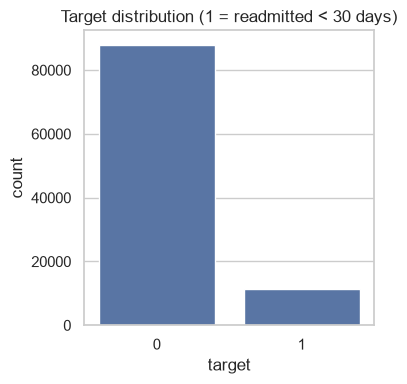

In [35]:
#binary target: 1 if the patient is readmitted within 30 days and 0 otherwise
df["target"] = (df["readmitted"] == "<30").astype(int)
#remove the original column because it contains the answer
df = df.drop(columns=["readmitted"])
#count the negative and positive rows
print(df["target"].value_counts())
#show the proportion of each class
print(df["target"].value_counts(normalize=True).round(3))
#create the figure
plt.figure(figsize=(4, 4))
#draw the number of rows of each class
sns.countplot(x="target", data=df)
#add a title
plt.title("Target distribution (1 = readmitted < 30 days)")
#avoid overlapping texts
plt.tight_layout()
#display the graph
plt.show()

What this code does: the original column readmitted has three values (NO, >30 and <30). We transform it into a binary target. The target is 1 when the patient is readmitted in less than 30 days and 0 in all other cases. Then we drop the original column. If we kept it the model would simply read the answer in the features and this would be a leakage.

Why this choice: a readmission within 30 days is the one that is expensive for hospitals and it is the usual definition in the literature. The problem becomes a binary classification which is simpler to evaluate than three classes.

How to read the results: there are 88,026 rows with target 0 and 11,314 rows with target 1. The positive class represents only 11.4 percent of the data so the classes are strongly imbalanced. A model that always predicts 0 would have about 88.6 percent of accuracy without learning anything. So accuracy is a misleading metric here and we will use ROC-AUC and PR-AUC with the recall and the precision of the positive class.

## 9. Patients and repeated visits

Rows : 99340
Unique patients : 69987
count    69987.000000
mean         1.419406
std          1.086388
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         40.000000
dtype: float64


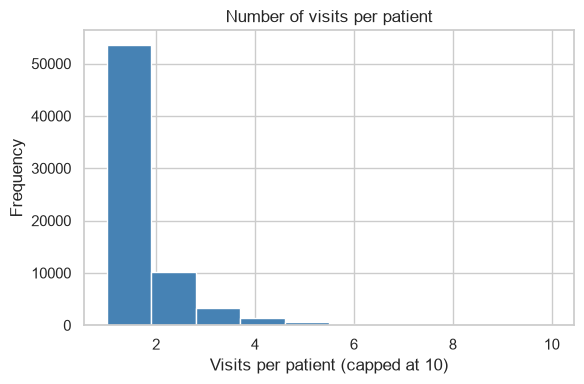

In [39]:
#number of hospital stays
print("Rows :", len(df))
#number of different patients
print("Unique patients :", df["patient_nbr"].nunique())
#number of stays of each patient
visits = df.groupby("patient_nbr").size()
#summary of the number of stays per patient
print(visits.describe())
#create the figure
plt.figure(figsize=(6, 4))
#draw the histogram with the values capped at 10
visits.clip(upper=10).plot(kind="hist", bins=10, color="steelblue")
#name the x axis
plt.xlabel("Visits per patient (capped at 10)")
#add a title
plt.title("Number of visits per patient")
#avoid overlapping texts
plt.tight_layout()
#display the graph
plt.show()
#remove the stay identifier because it is not a real feature
df = df.drop(columns=["encounter_id"])

What this code does: we count how many stays each patient has. We drop encounter_id because it is only an identifier of the stay. We keep patient_nbr because we need it for the split in Part 2.

How to read the results: there are 69,987 patients for 99,340 rows so the same patient appears several times (1.42 stays on average and up to 40 stays for one patient). The histogram shows that most patients have only one stay. This is very important for the evaluation. With a random split the same patient could be in the training set and in the test set. The model could then recognise the patient and the test score would be too optimistic. This is a data leakage. This is why we split by patient in Part 2.

## 10. Exploratory analysis

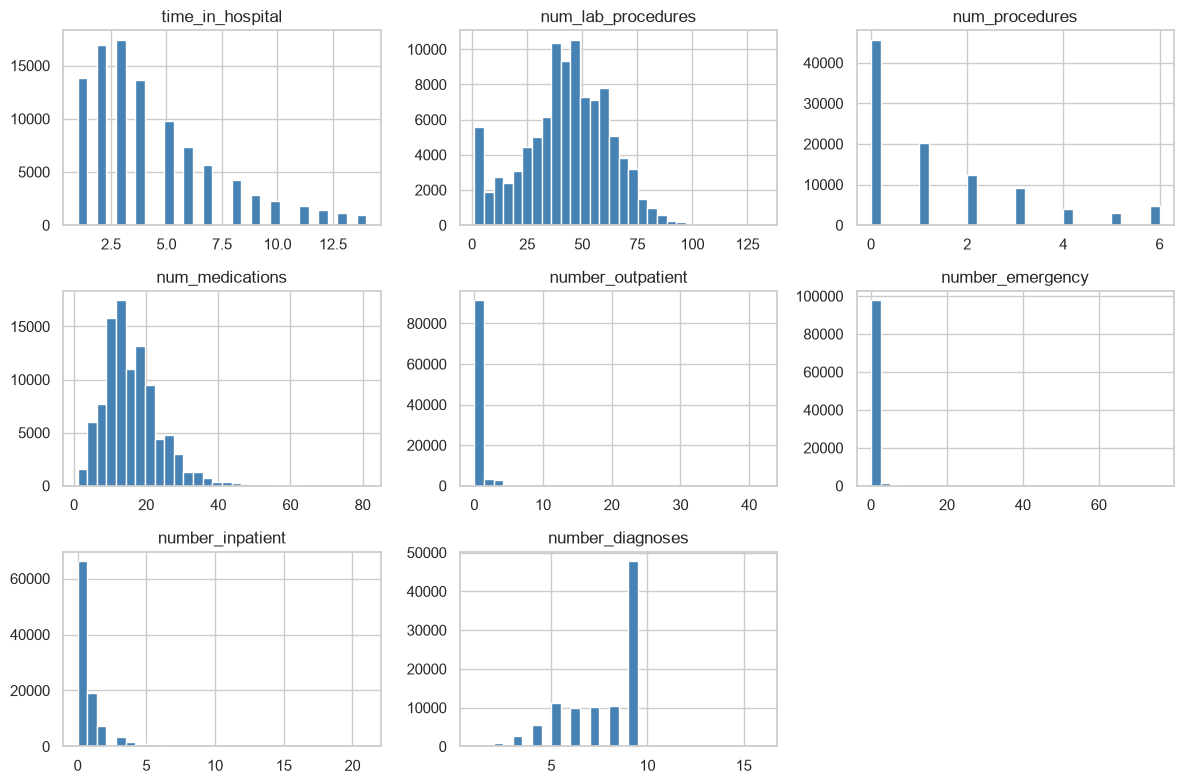

In [43]:
#list of the real numeric variables
EDA_NUM_COLS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
#draw one histogram per numeric variable
df[EDA_NUM_COLS].hist(bins=30, figsize=(12, 8), color="steelblue")
#avoid overlapping texts
plt.tight_layout()
#display the histograms
plt.show()

What this code does: we draw one histogram per numeric variable to see its distribution.

How to read the results: number_outpatient, number_emergency and number_inpatient are strongly skewed. Most patients have 0 and a few patients have large values. time_in_hospital is also shifted to the left with most stays between 1 and 6 days. The large values are possible from a medical point of view so we do not remove them as outliers. Tree based models handle them well and for the logistic regression the standardisation of Part 2 reduces the problem of scale.

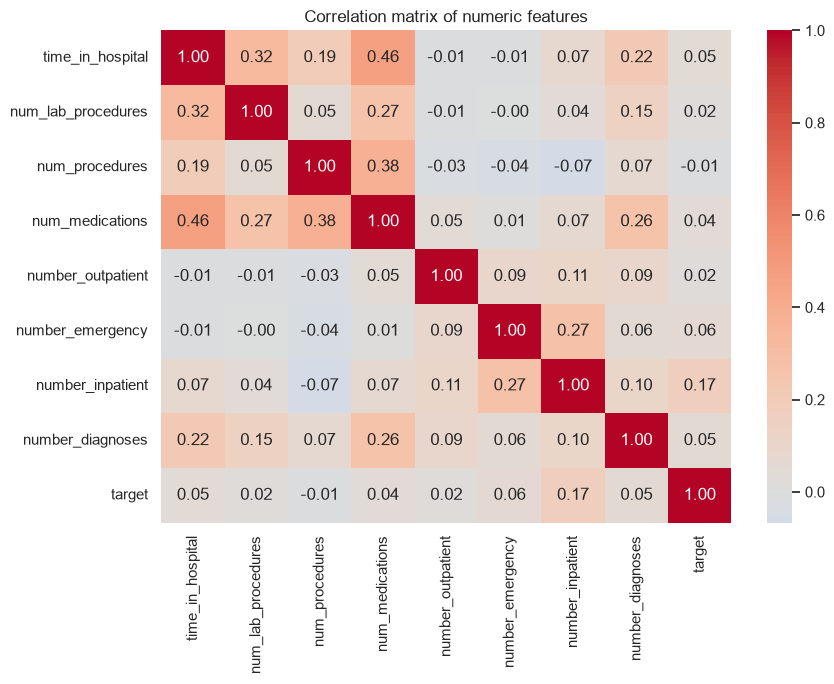

In [46]:
#compute the Pearson correlations between the numeric variables and the target
corr = df[EDA_NUM_COLS + ["target"]].corr()
#create the figure
plt.figure(figsize=(9, 7))
#draw the heatmap with the values written in each cell
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
#add a title
plt.title("Correlation matrix of numeric features")
#avoid overlapping texts
plt.tight_layout()
#display the heatmap
plt.show()

What this code does: the Pearson correlation measures the linear link between two variables. It goes from -1 (perfect opposite link) to 1 (perfect same direction link) and 0 means no linear link. We compute it between all the numeric variables and the target.

How to read the results: the correlations with the target are weak and usually below 0.1. number_inpatient is normally the strongest one. This tells us that the problem is difficult and that we should expect a modest AUC. We also see that some features are correlated with each other (for example time_in_hospital, num_medications and num_lab_procedures). So there is a bit of redundancy between them.

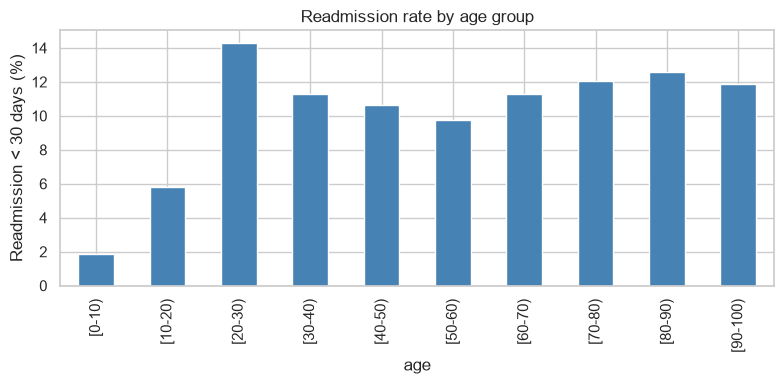

In [48]:
#readmission rate in percent for each age group
age_rate = df.groupby("age")["target"].mean().mul(100)
#create the figure
plt.figure(figsize=(8, 4))
#draw one bar per age group
age_rate.plot(kind="bar", color="steelblue")
#name the y axis
plt.ylabel("Readmission < 30 days (%)")
#add a title
plt.title("Readmission rate by age group")
#avoid overlapping texts
plt.tight_layout()
#display the graph
plt.show()

What this code does: for each age group we compute the mean of the target. Since the target is 0 or 1 this mean is the readmission rate.

How to read the results: the rate changes with the age. It is usually lower for the youngest patients and a little higher for older patients. The difference stays modest so the age alone is not enough to predict a readmission.

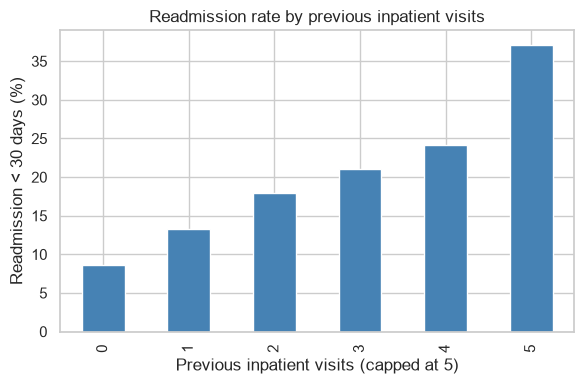

In [52]:
#group the values above 5 in a single class
inp = df["number_inpatient"].clip(upper=5)
#readmission rate in percent according to the number of previous inpatient visits
inp_rate = df.groupby(inp)["target"].mean().mul(100)
#create the figure
plt.figure(figsize=(6, 4))
#draw one bar per value
inp_rate.plot(kind="bar", color="steelblue")
#name the x axis
plt.xlabel("Previous inpatient visits (capped at 5)")
#name the y axis
plt.ylabel("Readmission < 30 days (%)")
#add a title
plt.title("Readmission rate by previous inpatient visits")
#avoid overlapping texts
plt.tight_layout()
#display the graph
plt.show()

What this code does: it is the same calculation as for the age but with the number of previous inpatient visits. We cap the value at 5 because larger values are rare.

How to read the results: the readmission rate increases clearly when the number of previous visits increases. It is one of the most informative variables of the dataset. We expect to find it again at the top of the feature selection later in the project.

## 11. Final check and saving the cleaned data

In [56]:
#print the final size of the table
print("Final shape :", df.shape)
#print the proportion of positive rows
print("Positive rate :", round(df["target"].mean(), 3))
#check that patient_nbr is still in the table
print("Unique patients :", df["patient_nbr"].nunique())
#print the columns that still have missing values
print(df.isna().sum()[df.isna().sum() > 0])
#create the output folder if it does not exist
os.makedirs(PROCESSED_DIR, exist_ok=True)
#save the cleaned data
df.to_csv(os.path.join(PROCESSED_DIR, "diabetes_clean.csv"), index=False)
#confirm the saving
print("Saved in", PROCESSED_DIR)

Final shape : (99340, 34)
Positive rate : 0.114
Unique patients : 69987
diag_1      20
diag_2     356
diag_3    1419
dtype: int64
Saved in ..\data\processed


Summary of the cleaning decisions:
- the question marks became NaN and the text None was kept as a real category
- weight and payer_code were removed
- medical_specialty and race received a constant category for their missing values
- the invalid genders and the patients who died or went to hospice were removed
- the constant and quasi-constant columns were removed
- the binary target was created and the column readmitted was removed
- patient_nbr was kept for the split and encounter_id was removed

The cleaned data are saved in diabetes_clean.csv. This file is the clean dataset of the project and a checkpoint. We continue to work with the table df in memory and we do not reload the file. If someone reloads it with a normal read_csv pandas will transform the text None into NaN again. In that case the options keep_default_na=False and na_values=[""] must be used. No scaling and no encoding was done in Part 1 to avoid any leakage.

# Part 2 - Preprocessing and train/test split
In this part we prepare the cleaned data for the models. We create a few simple features and we split the data by patient. Then we build the preprocessing pipeline and we check that nothing leaks from the test set.

## 12. Shared preprocessing module (src/preprocessing.py)

The baseline and the models need exactly the same preprocessing as this notebook. If we copy and paste the code in each notebook it is very easy to change one version and forget the others. For this reason we write the code once in a Python file called preprocessing.py inside the src folder and we import it everywhere.

The module contains five parts:
- icd9_to_group: turns an ICD-9 diagnosis code into one of 10 big groups (Circulatory, Respiratory, Digestive, Diabetes, Injury, Musculoskeletal, Genitourinary, Neoplasms, Other and Missing). The groups are similar to the ones used by the authors of the original dataset (Strack et al. 2014).
- age_to_number: turns an age bin such as [70-80) into its middle value (75).
- prepare_features: applies all the row by row transformations.
- get_column_types: separates numeric and categorical columns.
- build_preprocessor: builds the ColumnTransformer. It is returned unfitted on purpose.

The module is stateless. None of its functions learns anything from the data so using them before the split does not create any leakage. The first cell below creates the folder and the second cell writes the file and the third cell imports it.

In [62]:
#create the src folder if it does not exist yet
os.makedirs(SRC_DIR, exist_ok=True)

In [64]:
%%writefile ../src/preprocessing.py
#import pandas to manipulate the tables
import pandas as pd
#import the tool that applies different steps to different columns
from sklearn.compose import ColumnTransformer
#import the tool that fills missing values
from sklearn.impute import SimpleImputer
#import the pipeline to chain steps together
from sklearn.pipeline import Pipeline
#import the encoder for categories and the scaler for numbers
from sklearn.preprocessing import OneHotEncoder, StandardScaler

#columns that are codes and not real numbers
ID_COLS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
#columns that contain ICD-9 diagnosis codes
DIAG_COLS = ["diag_1", "diag_2", "diag_3"]
#columns where None means that the test was not done
TEST_COLS = ["max_glu_serum", "A1Cresult"]
#all the medication columns of the original dataset (only the ones still present are used)
MED_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]


#function that turns one ICD-9 code into a big diagnosis group
def icd9_to_group(code):
    #missing codes get their own group
    if pd.isna(code):
        #return the missing group
        return "Missing"
    #make sure the code is a text
    code = str(code)
    #codes starting with V or E are supplementary codes
    if code.startswith(("V", "E")):
        #return the other group
        return "Other"
    #try to convert the code to a number
    try:
        #keep the number so we can compare it with ranges
        number = float(code)
    #if the code is not a number
    except ValueError:
        #return the other group
        return "Other"
    #a text like nan is also a missing code
    if pd.isna(number):
        #return the missing group
        return "Missing"
    #diabetes codes are 250.xx
    if 250 <= number < 251:
        #return the diabetes group
        return "Diabetes"
    #circulatory system codes
    if 390 <= number <= 459 or int(number) == 785:
        #return the circulatory group
        return "Circulatory"
    #respiratory system codes
    if 460 <= number <= 519 or int(number) == 786:
        #return the respiratory group
        return "Respiratory"
    #digestive system codes
    if 520 <= number <= 579 or int(number) == 787:
        #return the digestive group
        return "Digestive"
    #injury and poisoning codes
    if 800 <= number <= 999:
        #return the injury group
        return "Injury"
    #musculoskeletal system codes
    if 710 <= number <= 739:
        #return the musculoskeletal group
        return "Musculoskeletal"
    #genitourinary system codes
    if 580 <= number <= 629 or int(number) == 788:
        #return the genitourinary group
        return "Genitourinary"
    #neoplasm codes
    if 140 <= number <= 239:
        #return the neoplasms group
        return "Neoplasms"
    #everything else
    return "Other"


#function that turns an age bin like [70-80) into its middle value
def age_to_number(age_bin):
    #take the lower bound of the bin as a number
    lower = int(age_bin[1:age_bin.index("-")])
    #return the middle of the bin
    return lower + 5


#function that prepares the features row by row (nothing is learned from the data here)
def prepare_features(df):
    #work on a copy so the original table is not changed
    df = df.copy()
    #loop over the id columns
    for col in ID_COLS:
        #convert the codes to text so they are treated as categories
        df[col] = df[col].astype(str)
    #loop over the diagnosis columns
    for col in DIAG_COLS:
        #replace each ICD-9 code by its big group
        df[col] = df[col].apply(icd9_to_group)
    #loop over the test result columns
    for col in TEST_COLS:
        #the text None (or a missing value) means that the test was not done so we give it a clear name
        df[col] = df[col].fillna("None").replace("None", "NotMeasured")
    #create a numeric age with the middle of each bin
    df["age_num"] = df["age"].apply(age_to_number)
    #drop the original text age
    df = df.drop(columns=["age"])
    #keep only the medication columns that are still in the table
    meds = [c for c in MED_COLS if c in df.columns]
    #count how many medications the patient takes
    df["n_meds_used"] = (df[meds] != "No").sum(axis=1)
    #count how many medications had their dose changed (Up or Down)
    df["n_meds_changed"] = df[meds].isin(["Up", "Down"]).sum(axis=1)
    #return the prepared table
    return df


#function that splits the columns into numeric and categorical
def get_column_types(X):
    #numeric columns
    num_cols = X.select_dtypes(include="number").columns.tolist()
    #all the other columns are categorical
    cat_cols = X.select_dtypes(exclude="number").columns.tolist()
    #return both lists
    return num_cols, cat_cols


#function that builds the preprocessing (it is NOT fitted here)
def build_preprocessor(num_cols, cat_cols):
    #pipeline for the numeric columns
    numeric_pipe = Pipeline([
        #fill missing numbers with the median of the training data
        ("imputer", SimpleImputer(strategy="median")),
        #standardize to mean 0 and standard deviation 1
        ("scaler", StandardScaler()),
    ])
    #pipeline for the categorical columns
    categorical_pipe = Pipeline([
        #fill missing categories with the most frequent one
        ("imputer", SimpleImputer(strategy="most_frequent")),
        #one-hot encoding with a bucket for rare categories (less than 0.5 percent)
        ("encoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005)),
    ])
    #combine both pipelines in one transformer
    preprocessor = ColumnTransformer(
        #list of (name, transformer, columns)
        [("num", numeric_pipe, num_cols), ("cat", categorical_pipe, cat_cols)],
        #always return a dense array
        sparse_threshold=0,
    )
    #return the unfitted preprocessor
    return preprocessor

Overwriting ../src/preprocessing.py


In [66]:
#add the src folder to the Python path
sys.path.append(SRC_DIR)
#import the functions of our module
from preprocessing import prepare_features, get_column_types, build_preprocessor

If the import fails the most common reason is that the previous cell was not run or that the notebook is not started from the notebooks folder.

## 13. Feature preparation (row by row only)

A1Cresult
None    82506
>8       8137
Norm     4922
>7       3775
Name: count, dtype: int64
   age_num  n_meds_used  n_meds_changed     diag_1     diag_2       diag_3
0        5            0               0   Diabetes    Missing      Missing
1       15            1               1      Other   Diabetes        Other
2       25            1               0      Other   Diabetes        Other
3       35            1               1      Other   Diabetes  Circulatory
4       45            2               0  Neoplasms  Neoplasms     Diabetes
diag_1
Circulatory        29680
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6851
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Missing               20
Name: count, dtype: int64


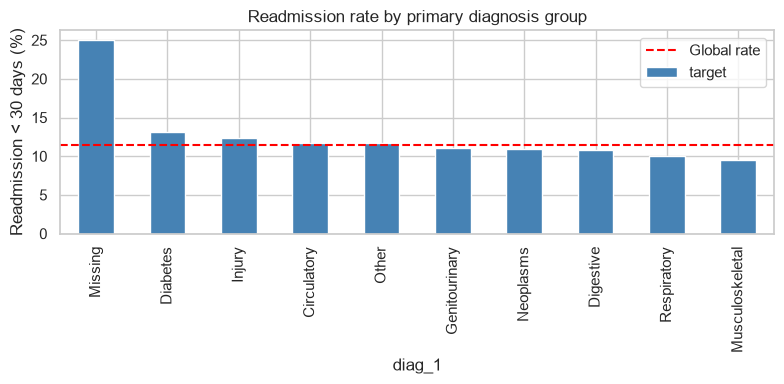

Series([], dtype: int64)


In [70]:
#check that the two columns we need for the split are present
assert "patient_nbr" in df.columns and "target" in df.columns
#check that None is still a text category in a test column
print(df["A1Cresult"].value_counts())
#apply the row by row feature preparation to the cleaned data
df_feat = prepare_features(df)
#show the new and transformed columns
print(df_feat[["age_num", "n_meds_used", "n_meds_changed", "diag_1", "diag_2", "diag_3"]].head())
#count the rows in each group of the first diagnosis
print(df_feat["diag_1"].value_counts())
#compute the readmission rate in percent for each group of the first diagnosis
diag_rate = df_feat.groupby("diag_1")["target"].mean().mul(100).sort_values(ascending=False)
#create the figure
plt.figure(figsize=(8, 4))
#draw one bar per diagnosis group
diag_rate.plot(kind="bar", color="steelblue")
#draw a horizontal line with the global readmission rate
plt.axhline(df_feat["target"].mean() * 100, color="red", linestyle="--", label="Global rate")
#name the y axis
plt.ylabel("Readmission < 30 days (%)")
#add a title
plt.title("Readmission rate by primary diagnosis group")
#show the legend
plt.legend()
#avoid overlapping texts
plt.tight_layout()
#display the graph
plt.show()
#check how many missing values are left in the table
print(df_feat.isna().sum()[df_feat.isna().sum() > 0])

What this code does:
- ICD-9 grouping. The columns diag_1, diag_2 and diag_3 contain hundreds of different codes. If we applied one-hot encoding directly we would create hundreds of columns that are almost always zero. This makes the models slow and increases overfitting. Grouping the codes by medical family keeps the useful information and reduces the dimension.
- Numeric age. The age is given as ordered bins such as [0-10) or [70-80). Because the bins are ordered a single numeric column (the middle of the bin) is more compact than 10 dummy columns and keeps the order information.
- Medication counts. n_meds_used counts how many medications are different from No and n_meds_changed counts how many have a dose increase or decrease. These two columns summarise the medication columns in a simple way.
- Not measured tests. In max_glu_serum and A1Cresult the category None is renamed NotMeasured to make its meaning clear. If a missing value still appears in these columns (for example if the data were read with the default options) it is also turned into NotMeasured.
- The id columns (admission_type_id, discharge_disposition_id and admission_source_id) are converted to text so that they are treated as categories and not as numbers.

The function prepare_features works on the table df that is already in memory so we do not reload the saved file. The assert and the value counts at the beginning check that the table is in the expected state. None should still be a text category in A1Cresult and appear about 82,500 times.

How to read the results: the readmission rate changes only a little between diagnosis groups. Most groups stay close to the global rate (the red line of about 11 percent). The Diabetes group and some groups with a low rate are the ones that move the most but the differences remain small. So the diagnosis alone will not predict readmission well and this confirms that the problem is hard. After this step no missing values should remain in the table because the missing diagnosis codes now have their own group.

## 14. Defining X, y and groups

In [73]:
#target vector (1 = readmitted within 30 days)
y = df_feat["target"]
#group vector: the patient identifier (used to keep each patient in one set only)
groups = df_feat["patient_nbr"]
#feature table: everything except the target and the patient identifier
X = df_feat.drop(columns=["target", "patient_nbr"])
#print the shapes of the three objects
print("X :", X.shape, "| y :", y.shape, "| groups :", groups.shape)

X : (99340, 34) | y : (99340,) | groups : (99340,)


We separate the three objects that scikit-learn needs. X contains the features and y is the target. The vector groups contains patient_nbr and tells the splitter which rows belong to the same patient. patient_nbr is removed from X because it is only an identifier. If the model could use it the model would just memorise patients and the evaluation would be meaningless. We keep it in a separate vector because we need it for the split here and for the cross-validation in the next notebooks.

## 15. Train/test split by patient

In [78]:
#create the splitter with 5 folds (one fold is 20 percent of the patients)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
#take the first split only: its test fold becomes our final test set
train_idx, test_idx = next(sgkf.split(X, y, groups=groups))
#build the training features and the test features
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
#build the training target and the test target
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
#build the training groups and the test groups
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]
#find the patients that appear in both sets
overlap = set(groups_train) & set(groups_test)
#print the number of shared patients
print("Patients in both sets :", len(overlap))
#stop the notebook if there is any overlap
assert len(overlap) == 0
#build a small table to compare the two sets
summary = pd.DataFrame({"rows": [len(y_train), len(y_test)], "patients": [groups_train.nunique(), groups_test.nunique()], "positive_rate_%": [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]}, index=["train", "test"])
#display the table
summary

Patients in both sets : 0


,rows,patients,positive_rate_%
train,79473,56036,11.39
test,19867,13951,11.39


What this code does: StratifiedGroupKFold cuts the data into 5 folds. It respects two constraints at the same time. First all the rows of one patient go to the same fold (this is the group part). Second each fold tries to keep the same proportion of positive rows as the whole dataset (this is the stratified part). We use only the first split and we call its test fold our test set. This gives a split of about 80 percent for training and 20 percent for testing. shuffle=True mixes the groups before the cut and random_state makes the result reproducible. Without the shuffle the split would depend on the order of the rows in the file.

Why not a simple train_test_split? In this dataset one patient can have up to 40 hospital stays (see section 9). With a random split the same patient would be in train and test. The model could then recognise the patient and the test score would be too optimistic. This is a data leakage. GroupShuffleSplit would solve the patient problem but it does not control the proportion of positive rows.

How to read the results: the number of shared patients must be exactly 0 and the assert checks it. The two sets should have about 80 percent and 20 percent of the rows. The positive rate should be very close to 11.4 percent in both sets. The two rates are not exactly equal because the algorithm is approximate (it cannot cut a patient in two) but a difference of a few tenths of a percent is normal and acceptable.

## 16. Saving train and test files

In [81]:
#put the training features and the training target in one table and add the patient id back
train = X_train.assign(target=y_train, patient_nbr=groups_train)
#do the same for the test set
test = X_test.assign(target=y_test, patient_nbr=groups_test)
#save the training file
train.to_csv(os.path.join(PROCESSED_DIR, "train.csv"), index=False)
#save the test file
test.to_csv(os.path.join(PROCESSED_DIR, "test.csv"), index=False)
#print the sizes of the saved files
print("train :", train.shape, "| test :", test.shape)

train : (79473, 36) | test : (19867, 36)


We save the two sets in data/processed so that the next notebooks start from exactly the same split. The files contain the prepared features and also target and patient_nbr. The patient_nbr column will be used as the groups argument in the cross-validation and removed from X just before training.

The test file is locked from now on. We do not look at it and we do not tune anything on it. We only use it once at the end of the project. If we used it several times to choose a model our final score would be biased because we would have indirectly trained on it.

## 17. Preprocessing pipeline

In [84]:
#get the lists of numeric and categorical columns from the training features
num_cols, cat_cols = get_column_types(X_train)
#print the number of columns of each type
print("Numeric columns :", len(num_cols), "| Categorical columns :", len(cat_cols))
#print the names of the numeric columns
print(num_cols)
#print the names of the categorical columns
print(cat_cols)
#build the preprocessor (it is not fitted yet)
preprocessor = build_preprocessor(num_cols, cat_cols)
#display the structure of the preprocessor
preprocessor

Numeric columns : 11 | Categorical columns : 23
['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'age_num', 'n_meds_used', 'n_meds_changed']
['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. 

The ColumnTransformer applies a different treatment to each type of column and puts the results side by side:
- Numeric columns go through a SimpleImputer with the median and then through a StandardScaler. The median is preferred to the mean because several variables are very skewed (see the histograms in section 10) and the median is not affected by extreme values. The StandardScaler gives each column a mean of 0 and a standard deviation of 1. This is necessary for the logistic regression and for the Lasso because their penalty depends on the scale of the variables. It does not hurt tree based models.
- Categorical columns go through a SimpleImputer with the most frequent value and then through a OneHotEncoder. One-hot encoding creates one 0/1 column per category. The option min_frequency=0.005 puts all the categories that represent less than 0.5 percent of the rows in a single bucket called infrequent. This avoids many noisy columns for very rare values. The option handle_unknown="infrequent_if_exist" prevents an error if a category appears in a validation fold but not in the training fold.

We should have 11 numeric columns and 23 categorical columns. The preprocessor displayed above is only a recipe. Nothing has been learned yet.

## 18. Sanity check: no leakage

In [87]:
#fit the preprocessor on the training set only and transform it
X_train_t = preprocessor.fit_transform(X_train)
#transform the test set with what was learned on the training set
X_test_t = preprocessor.transform(X_test)
#print the shapes after transformation
print("Train :", X_train_t.shape, "| Test :", X_test_t.shape)
#get the number of numeric columns (they come first in the output)
k = len(num_cols)
#print the mean of the first scaled numeric columns on the training set
print("Train means :", np.round(X_train_t[:, :k].mean(axis=0)[:5], 4))
#print the mean of the same columns on the test set
print("Test means  :", np.round(X_test_t[:, :k].mean(axis=0)[:5], 4))
#print the standard deviation of the same columns on the training set
print("Train stds  :", np.round(X_train_t[:, :k].std(axis=0)[:5], 4))
#print the first names of the output features
print(preprocessor.get_feature_names_out()[:10])

Train : (79473, 138) | Test : (19867, 138)
Train means : [ 0.  0. -0.  0. -0.]
Test means  : [-0.0033  0.0107 -0.0112  0.0101  0.0049]
Train stds  : [1. 1. 1. 1. 1.]
['num__time_in_hospital' 'num__num_lab_procedures' 'num__num_procedures'
 'num__num_medications' 'num__number_outpatient' 'num__number_emergency'
 'num__number_inpatient' 'num__number_diagnoses' 'num__age_num'
 'num__n_meds_used']


This cell is only a demonstration. We call fit_transform on the training set and only transform on the test set. fit learns the medians, the means, the standard deviations and the list of categories. transform just applies them. The test set is never used to learn anything.

How to read the results: on the training set the means of the scaled columns are 0 and the standard deviations are 1 by construction. On the test set the means are close to 0 but not exactly 0 (for example 0.01 or -0.02). This is the proof that the test set was scaled with the statistics of the training set. If the test means were exactly 0 it would mean that the scaler was fitted on the test data and that we have a leakage. The number of columns after encoding is larger than the number of input columns because of one-hot encoding.

The fitted preprocessor of this cell is not saved and not reused. In the next notebooks we put a new preprocessor inside a Pipeline with the model. The Pipeline refits it again on the training part of each cross-validation fold so that the validation part is never used to learn anything.

## 19. Class imbalance

In [94]:
#count the negative rows in the training set
n_neg = (y_train == 0).sum()
#count the positive rows in the training set
n_pos = (y_train == 1).sum()
#print the two counts
print("Negatives :", n_neg, "| Positives :", n_pos)
#print how many negatives there are for one positive
print("Ratio negatives / positives :", round(n_neg / n_pos, 2))

Negatives : 70422 | Positives : 9051
Ratio negatives / positives : 7.78


The target is imbalanced: there are about 8 negative rows for each positive row. We do not apply any resampling in this notebook. SMOTE or undersampling must never be applied before the split or before the cross-validation because synthetic or duplicated rows would end up in both the training part and the validation part and the scores would be inflated. The test set must also never be resampled because it has to keep the real distribution of the data.

The plan for the next notebooks is:
- Baseline: use class_weight="balanced" in the logistic regression so that errors on the rare class cost more. We also compare with a DummyClassifier. Since accuracy is misleading here (a model that always predicts 0 gets about 89 percent) we use ROC-AUC and PR-AUC with the recall and precision of the positive class.
- Models: compare class weights with resampling methods (undersampling or SMOTE) placed inside an imblearn Pipeline so that they are applied only on the training part of each fold. The decision threshold is also tuned on the out-of-fold predictions only and then frozen before the single evaluation on the test set.

## 20. Summary

What was done in this notebook:
- Part 1: the raw data were loaded and cleaned (missing values, invalid rows and constant columns) and the binary target was created. A first exploratory analysis showed a positive rate of 11.4 percent and weak correlations with the target.
- The cleaned data were saved in diabetes_clean.csv.
- Part 2: the module src/preprocessing.py was created with the row by row feature functions and the unfitted preprocessor.
- ICD-9 codes were grouped, age became numeric, medication counts were added and the test result None was renamed NotMeasured.
- The data were split by patient into about 80 percent train and 20 percent test with the same proportion of positives. The number of shared patients is 0.
- train.csv and test.csv were saved in data/processed.
- The preprocessor was checked on the training set to prove that no information comes from the test set.

Next step: the baseline notebook loads train.csv and builds the baseline (DummyClassifier and logistic regression) with StratifiedGroupKFold and groups=patient_nbr. The test set stays untouched until the final evaluation.